Environment: the `etunc` kernel (pixi env `etunc`, with the repo installed editable).

# CLARA-A3 coverage vs. the ILAMB net radiation products

CLARA-A3 (EUMETSAT CM SAF, 0.25°, 1979-2020) covers all of `TIME_SLICE` (1995-2014), unlike the ILAMB Rn
products (GEWEX.SRB 1984-2007, CERESed4.2 2000-03 to 2023-06, CLASS 2003-2009). Its shortwave, and so its net
radiation `SRB`, is missing in low-sun months, though. This notebook compares the spatial and temporal coverage
of net radiation over land:

1. Gridcells and land area covered, on the native grids and on the pipeline's target grid
2. Maps of coverage on the native grids (valid months, complete years, CLARA-A3's seasonal gaps)
3. Timeseries of global and regional area-weighted valid land area and Rn
4. Climatological Rn maps and differences from CLARA-A3

Land is defined as in `scripts/prep_obs.py` (step 5): Natural Earth land by cell center, without Greenland and
Iceland, within `LAT_BNDS` (no Antarctica). "Complete year" follows step 4: a gridcell-year needs all 12 months.

In [1]:
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import cartopy.crs as ccrs

import etunc.config as cfg
import etunc.binning as binning
import etunc.edges as edges
import etunc.grid as rg
import etunc.plotting as plotting
import etunc.temporal as temporal
import etunc.units as units
import etunc.load.ilamb as il
import etunc.load.obs as lo

In [2]:
# TIME_SLICE = cfg.TIME_SLICE    # pipeline period, used for the coverage statistics and shaded in the timeseries
# TIME_SLICE = slice("1995-01", "2014-12")
# TIME_SLICE = slice("1985-01", "2004-12")
TIME_SLICE = slice("2001-01", "2014-12")
TARGET_RES = cfg.TARGET_RES    # pipeline target grid (deg)
PERIOD = temporal.format_time_period(TIME_SLICE)

ILAMB_RN = list(il.PRODUCTS["rn"])   # CERESed4.2, CLASS, GEWEX.SRB
PRODUCTS = ["CLARA-A3", *ILAMB_RN]
COLORS = {"CLARA-A3": "k", "GEWEX.SRB": "tab:blue", "CERESed4.2": "tab:orange", "CLASS": "tab:green"}

# Latitude bands for the regional averages, chosen to separate CLARA-A3's low-sun gaps (mid/high latitudes)
# from the tropics
REGIONS = {
    "Global":                   cfg.LAT_BNDS,
    "NH high (50N-90N)":        slice(50, 90),
    "NH mid (23N-50N)":         slice(23, 50),
    "Tropics (23S-23N)":        slice(-23, 23),
    "SH extratropics (58S-23S)": slice(-58, -23),
}

## Load monthly Rn on the native grids

In [3]:
def month_start(da: xr.DataArray) -> xr.DataArray:
    """Time stamps set to the first of the month (datetime64), so all products share one monthly axis."""
    # ILAMB stamps mid-month on a noleap calendar, CLARA-A3 the first of the month
    time = pd.to_datetime(pd.DataFrame({"year": da.time.dt.year.values, "month": da.time.dt.month.values, "day": 1}))
    return da.assign_coords(time=time.values)


rn = {"CLARA-A3": lo.load_obs("clara", "SRB")}  # full record, W m-2
for p in ILAMB_RN:
    rn[p] = units.flux_to_wm2(il.load_native("rn", p, slice(None, None)))
# Pipeline domain without Antarctica; LAT_BNDS (-58) is a cell edge of every grid
rn = {p: month_start(da.sel(lat=cfg.LAT_BNDS)).load().rename("rn") for p, da in rn.items()}

for p, da in rn.items():
    print(f"{p:11}: {rg.native_res(da):>16}, {str(da.time.values[0])[:7]} to {str(da.time.values[-1])[:7]} "
          f"({da.sizes['time']} months)")

CLARA-A3   :  0.25 x 0.25 deg, 1979-01 to 2020-12 (504 months)
CERESed4.2 :        1 x 1 deg, 2000-03 to 2023-06 (280 months)
CLASS      :    0.5 x 0.5 deg, 2003-01 to 2009-12 (84 months)
GEWEX.SRB  :    0.5 x 0.5 deg, 1984-01 to 2007-12 (288 months)


In [4]:
# Land mask as in prep_obs.py step 5: Natural Earth land by cell center, without Greenland/Iceland
land = {p: rg.landne_mask(da) for p, da in rn.items()}
# Land area of each native cell [km2], 0 over ocean
area = {
    p: xr.DataArray(rg.cell_area(da.lat.values, da.lon.values) / 1e6, coords={"lat": da.lat, "lon": da.lon}) * land[p]
    for p, da in rn.items()
}
# Valid: data on a land cell, per month
valid = {p: da.notnull() & land[p] for p, da in rn.items()}

## 1. Gridcells and land area covered

Native gridcell counts are not comparable across resolutions (0.25°, 0.5°, 1°), so coverage is given as land
area [10⁶ km²]. Columns, over `TIME_SLICE`:
- `years`: complete calendar years of the product inside `TIME_SLICE`
- `any valid month`: land with at least one valid month
- `>=1 complete year`: land with at least one year of 12 valid months (needed for a climatological Rn)
- `all years complete`: land with 12 valid months in every one of the product's years

In [26]:
def land_km2(mask: xr.DataArray, cell_km2: xr.DataArray) -> float:
    """Land area [10^6 km2] of the cells in `mask`."""
    return float(cell_km2.where(mask).sum()) / 1e6


def n_complete_years(v: xr.DataArray) -> xr.DataArray:
    """Years with all 12 months valid, per gridcell (the 12-month rule of prep_obs.py step 4)."""
    return (v.groupby("time.year").sum() == 12).sum("year")


n_years, n_complete, rows = {}, {}, {}
for p in PRODUCTS:
    v = valid[p].sel(time=TIME_SLICE)
    n_years[p] = len(temporal.complete_years(rn[p].sel(time=TIME_SLICE)))  # years with 12 months in the time axis
    n_complete[p] = n_complete_years(v)
    rows[p] = {
        "native res": rg.native_res(rn[p]),
        "record": f"{str(rn[p].time.values[0])[:7]} to {str(rn[p].time.values[-1])[:7]}",
        "years": n_years[p],
        "land cells": int(land[p].sum()),
        "land area [km2]": land_km2(land[p], area[p]),
        "any valid month [km2]": land_km2(v.any("time"), area[p]),
        ">=1 complete year [km2]": land_km2(n_complete[p] >= 1, area[p]),
        "all years complete [km2]": land_km2(n_complete[p] == n_years[p], area[p]),
    }
table_native = pd.DataFrame(rows).T.infer_objects()  # numeric columns back to numbers after the transpose
print(f"Native grids, {PERIOD}, land area in 10^6 km2")
table_native.round(2)

Native grids, 200101-201412, land area in 10^6 km2


,native res,record,years,land cells,land area [km2],any valid month [km2],>=1 complete year [km2],all years complete [km2]
CLARA-A3,0.25 x 0.25 deg,1979-01 to 2020-12,14,234344,132.04,132.04,94.97,68.03
CERESed4.2,1 x 1 deg,2000-03 to 2023-06,14,14661,132.10,132.10,132.10,132.10
CLASS,0.5 x 0.5 deg,2003-01 to 2009-12,7,58648,132.15,119.67,118.99,104.63
GEWEX.SRB,0.5 x 0.5 deg,1984-01 to 2007-12,7,58648,132.15,132.15,125.50,125.50


What the pipeline keeps: steps 4-8 and 10 of `prep_obs.py` for Rn over `TIME_SLICE` (annual means with the
12-month rule, land mask, conservative regridding to `TARGET_RES` with `NA_THRESH`, climatology). A target
gridcell has a climatological Rn if it has at least one valid year. Land area on the target grid is fractional
Natural Earth land (`rg.land_area`), so coastal cells count only their land part.

In [6]:
ann1, clim1 = {}, {}
for p in PRODUCTS:
    a = temporal.aggregate(rn[p].sel(time=TIME_SLICE), "year", label=p)
    a = rg.mask_to_land(a, land[p], p)
    regridder = rg.bounded_conservative_regridder(rg.bounded_src_grid(a), TARGET_RES)
    ann1[p] = rg.on_grid(rg.regrid_with_na_thresh(a, regridder, cfg.NA_THRESH), TARGET_RES, p).sel(lat=cfg.LAT_BNDS)
    clim1[p] = temporal.aggregate(ann1[p], "clim", label=p)

# Land area [km2] of each target cell, and the land the pipeline considers (no Greenland/Iceland)
land_area1 = rg.land_area(clim1["CLARA-A3"])
land_area1 = land_area1.where(rg.greenland_mask(land_area1), 0)

CLARA-A3: annual means of 14 complete years; 5560862 gridcell-years with partial (1-11) valid months, set to NaN


/glade/work/bbuchovecky/miniforge3/envs/etunc/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


CLARA-A3: climatology of 14 years; 2191 gridcells have missing years (fewest valid years: 1)
CERESed4.2: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN


/glade/work/bbuchovecky/miniforge3/envs/etunc/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


CERESed4.2: climatology of 14 years; 0 gridcells have missing years
CLASS: annual means of 7 complete years; 11436 gridcell-years with partial (1-11) valid months, set to NaN


/glade/work/bbuchovecky/miniforge3/envs/etunc/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


CLASS: climatology of 7 years; 565 gridcells have missing years (fewest valid years: 1)
GEWEX.SRB: annual means of 7 complete years; 242064 gridcell-years with partial (1-11) valid months, set to NaN


/glade/work/bbuchovecky/miniforge3/envs/etunc/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


GEWEX.SRB: climatology of 7 years; 0 gridcells have missing years


In [7]:
valid1 = {p: clim1[p].notnull() for p in PRODUCTS}
valid1["all four"] = xr.concat([valid1[p] for p in PRODUCTS], "p").all("p")

# Target gridcells with a climatological Rn, and their land area per region
table_1deg = pd.DataFrame({
    p: {"gridcells": int(v.sum()), **{r: land_km2(v.sel(lat=b), land_area1.sel(lat=b)) for r, b in REGIONS.items()}}
    for p, v in valid1.items()
}).T.astype({"gridcells": int})
region_land = pd.Series({r: float(land_area1.sel(lat=b).sum()) / 1e6 for r, b in REGIONS.items()})
print(f"{rg.grid_tag(TARGET_RES)} target grid, {PERIOD}: gridcells and land area [10^6 km2] with a climatological Rn")
print("Land area of each region [10^6 km2]:", region_land.round(1).to_dict())
display(table_1deg.round(1))
print("Percent of each region's land area")
display((100 * table_1deg[list(REGIONS)] / region_land).round(0))

1deg target grid, 200101-201412: gridcells and land area [10^6 km2] with a climatological Rn
Land area of each region [10^6 km2]: {'Global': 132.1, 'NH high (50N-90N)': 29.4, 'NH mid (23N-50N)': 42.5, 'Tropics (23S-23N)': 48.5, 'SH extratropics (58S-23S)': 11.6}


,gridcells,Global,NH high (50N-90N),NH mid (23N-50N),Tropics (23S-23N),SH extratropics (58S-23S)
CLARA-A3,8517,91.8,0.0,34.6,46.6,10.6
CERESed4.2,14661,128.0,28.3,41.6,46.8,11.2
CLASS,13079,119.2,25.3,39.5,44.1,10.3
GEWEX.SRB,12985,121.6,22.2,41.6,46.6,11.2
all four,7921,86.8,0.0,33.0,44.0,9.7


Percent of each region's land area


,Global,NH high (50N-90N),NH mid (23N-50N),Tropics (23S-23N),SH extratropics (58S-23S)
CLARA-A3,70.0,0.0,81.0,96.0,91.0
CERESed4.2,97.0,96.0,98.0,96.0,97.0
CLASS,90.0,86.0,93.0,91.0,89.0
GEWEX.SRB,92.0,75.0,98.0,96.0,97.0
all four,66.0,0.0,78.0,91.0,84.0


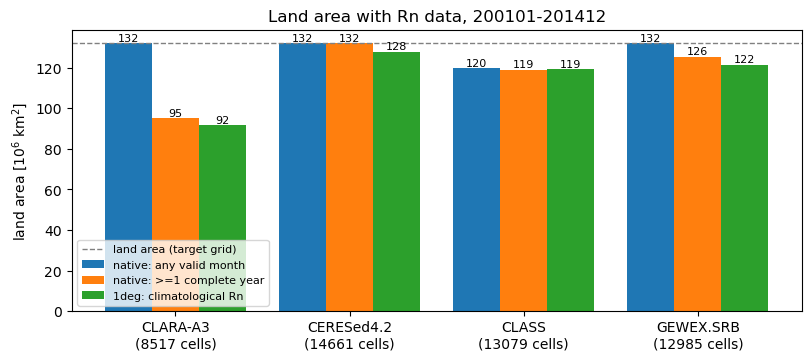

In [8]:
# Land area covered by each product: native grid (any valid month, >=1 complete year) and target grid
kinds = {
    "native: any valid month": table_native["any valid month"],
    "native: >=1 complete year": table_native[">=1 complete year"],
    f"{rg.grid_tag(TARGET_RES)}: climatological Rn": table_1deg.loc[PRODUCTS, "Global"],
}
fig, ax = plt.subplots(figsize=(8, 3.5), layout="constrained")
x, width = np.arange(len(PRODUCTS)), 0.27
for i, (kind, values) in enumerate(kinds.items()):
    bars = ax.bar(x + (i - 1) * width, values[PRODUCTS].astype(float), width, label=kind)
    ax.bar_label(bars, fmt="%.0f", fontsize=8)
# Target gridcell counts under the product names
ax.set_xticks(x, [f"{p}\n({table_1deg.loc[p, 'gridcells']} cells)" for p in PRODUCTS])
ax.axhline(region_land["Global"], color="gray", ls="--", lw=1, label="land area (target grid)")
ax.set_ylabel("land area [10$^6$ km$^2$]")
ax.set_title(f"Land area with Rn data, {PERIOD}")
ax.legend(fontsize=8, loc="lower left")
plt.show()

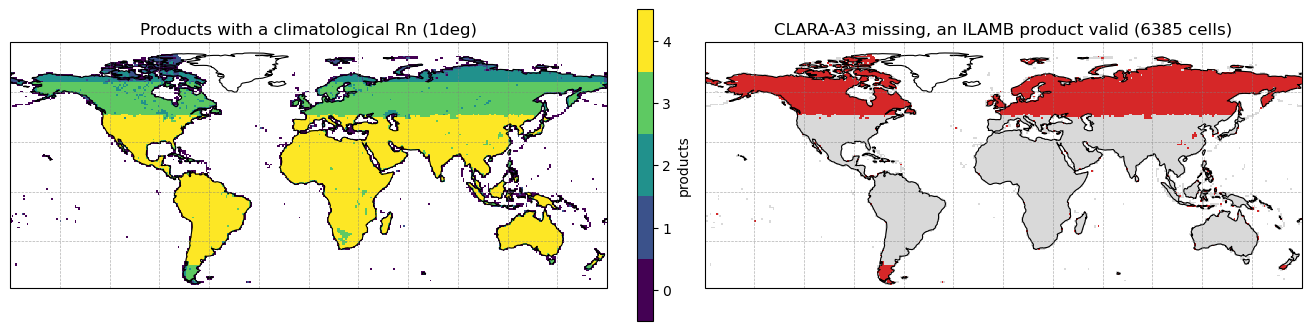

In [9]:
# Which products have a climatological Rn in each target cell, and where only CLARA-A3 is missing
n_products = sum(valid1[p].astype(int) for p in PRODUCTS).where(land_area1 > 0)
clara_lost = (~valid1["CLARA-A3"] & xr.concat([valid1[p] for p in ILAMB_RN], "p").any("p")).where(land_area1 > 0)

fig, axs = plotting.facets(2, ncols=2, maps=True, panel_size=(6.5, 3.2))
n_products.plot.pcolormesh(ax=axs[0], transform=ccrs.PlateCarree(), cmap=plt.get_cmap("viridis", 5),
                           vmin=-0.5, vmax=4.5, cbar_kwargs={"label": "products", "ticks": range(5)})
axs[0].set_title(f"Products with a climatological Rn ({rg.grid_tag(TARGET_RES)})")
clara_lost.plot.pcolormesh(ax=axs[1], transform=ccrs.PlateCarree(), cmap=mcolors.ListedColormap(["0.85", "tab:red"]),
                           add_colorbar=False)
axs[1].set_title(f"CLARA-A3 missing, an ILAMB product valid ({int(clara_lost.sum())} cells)")
for ax in axs:
    plotting.map_ax(ax, cfg.LAT_BNDS)
plt.show()

## 2. Maps of coverage on the native grids

Fraction of each product's months in `TIME_SLICE` with valid data, and fraction of its years that are complete.
A product's months/years are only those inside both its record and `TIME_SLICE`.

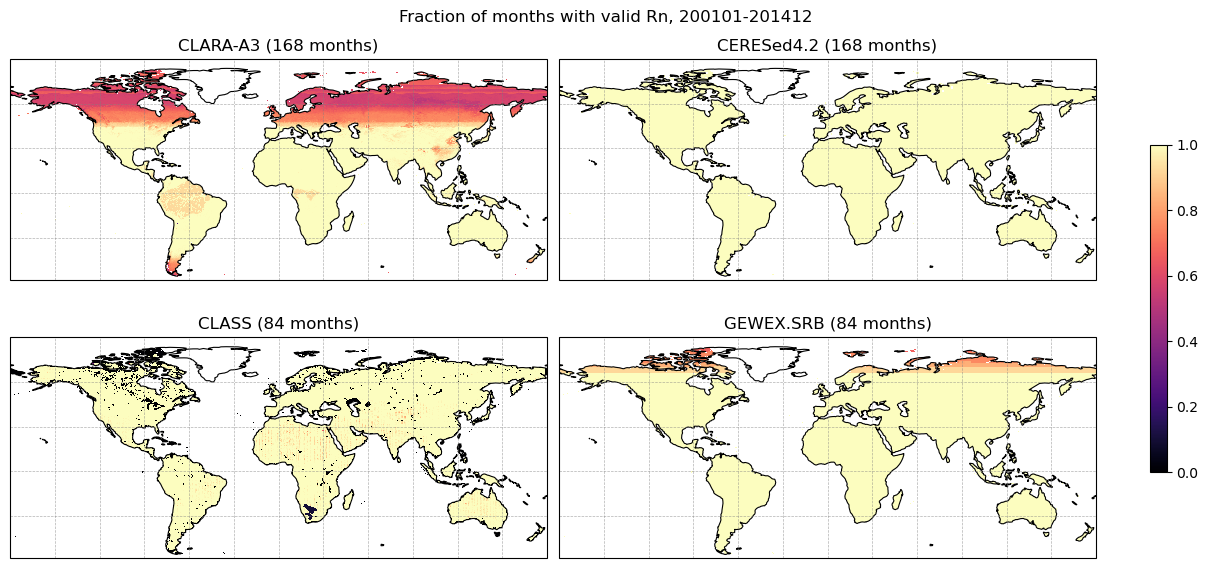

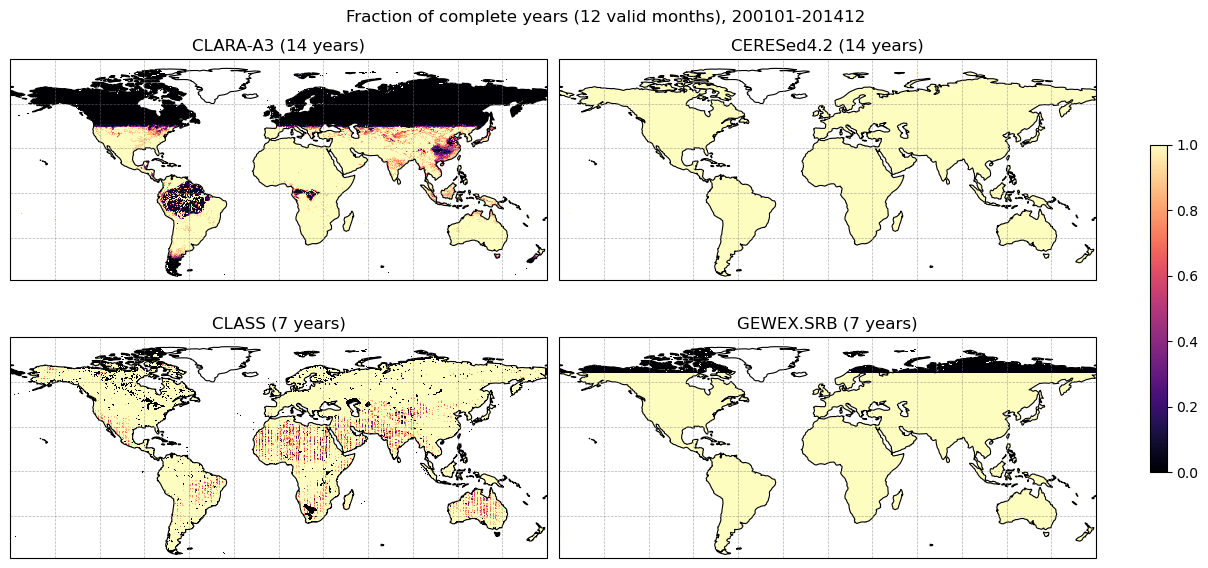

In [10]:
def map_panels(fields: dict, title: str, **kwargs):
    """One map per product (dict of (lat, lon) fields), sharing a colorbar."""
    fig, axs = plotting.facets(len(fields), ncols=2, maps=True, panel_size=(6.0, 2.9))
    for ax, (label, da) in zip(axs, fields.items()):
        im = da.plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), add_colorbar=False, **kwargs)
        ax.set_title(label)
        plotting.map_ax(ax, cfg.LAT_BNDS)
    fig.colorbar(im, ax=axs, shrink=0.6)
    fig.suptitle(title)
    plt.show()


frac_months = {
    f"{p} ({valid[p].sel(time=TIME_SLICE).sizes['time']} months)":
        (valid[p].sel(time=TIME_SLICE).mean("time")).where(land[p])
    for p in PRODUCTS
}
map_panels(frac_months, f"Fraction of months with valid Rn, {PERIOD}", vmin=0, vmax=1, cmap="magma")

frac_years = {f"{p} ({n_years[p]} years)": (n_complete[p] / n_years[p]).where(land[p]) for p in PRODUCTS}
map_panels(frac_years, f"Fraction of complete years (12 valid months), {PERIOD}", vmin=0, vmax=1, cmap="magma")

CLARA-A3's gaps by calendar month: the fraction of years in `TIME_SLICE` with valid Rn in each month. The
seasonal gaps follow low sun (winter at mid/high latitudes); in full polar night the shortwave is valid (0).

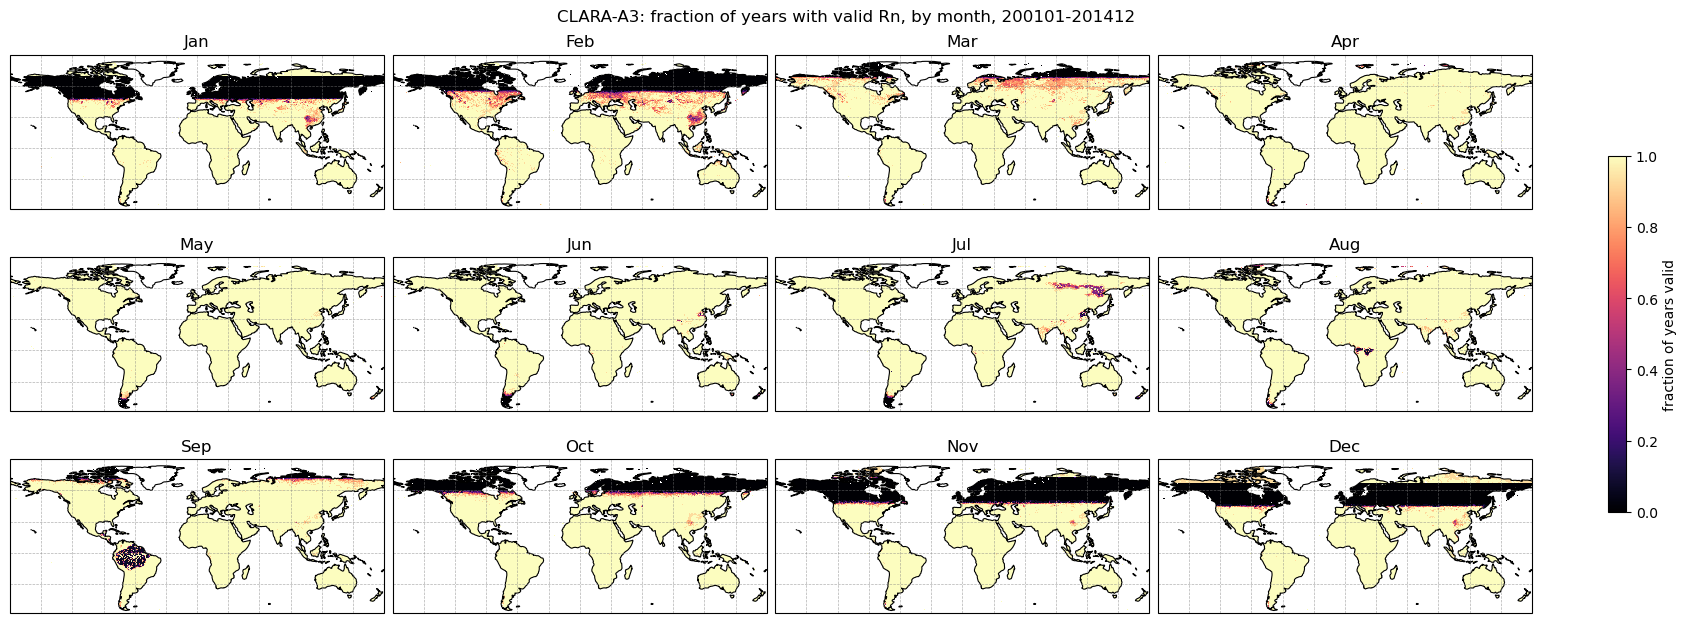

In [11]:
clara_month = valid["CLARA-A3"].sel(time=TIME_SLICE).groupby("time.month").mean().where(land["CLARA-A3"])
fig, axs = plotting.facets(12, ncols=4, maps=True, panel_size=(4.2, 2.1))
for ax, m in zip(axs, range(1, 13)):
    im = clara_month.sel(month=m).plot.pcolormesh(ax=ax, transform=ccrs.PlateCarree(), vmin=0, vmax=1, cmap="magma",
                                                  add_colorbar=False)
    ax.set_title(pd.Timestamp(2000, m, 1).strftime("%b"))
    plotting.map_ax(ax, cfg.LAT_BNDS)
fig.colorbar(im, ax=axs, shrink=0.6, label="fraction of years valid")
fig.suptitle(f"CLARA-A3: fraction of years with valid Rn, by month, {PERIOD}")
plt.show()

Valid fraction of the land area in each latitude row, over each product's full record.

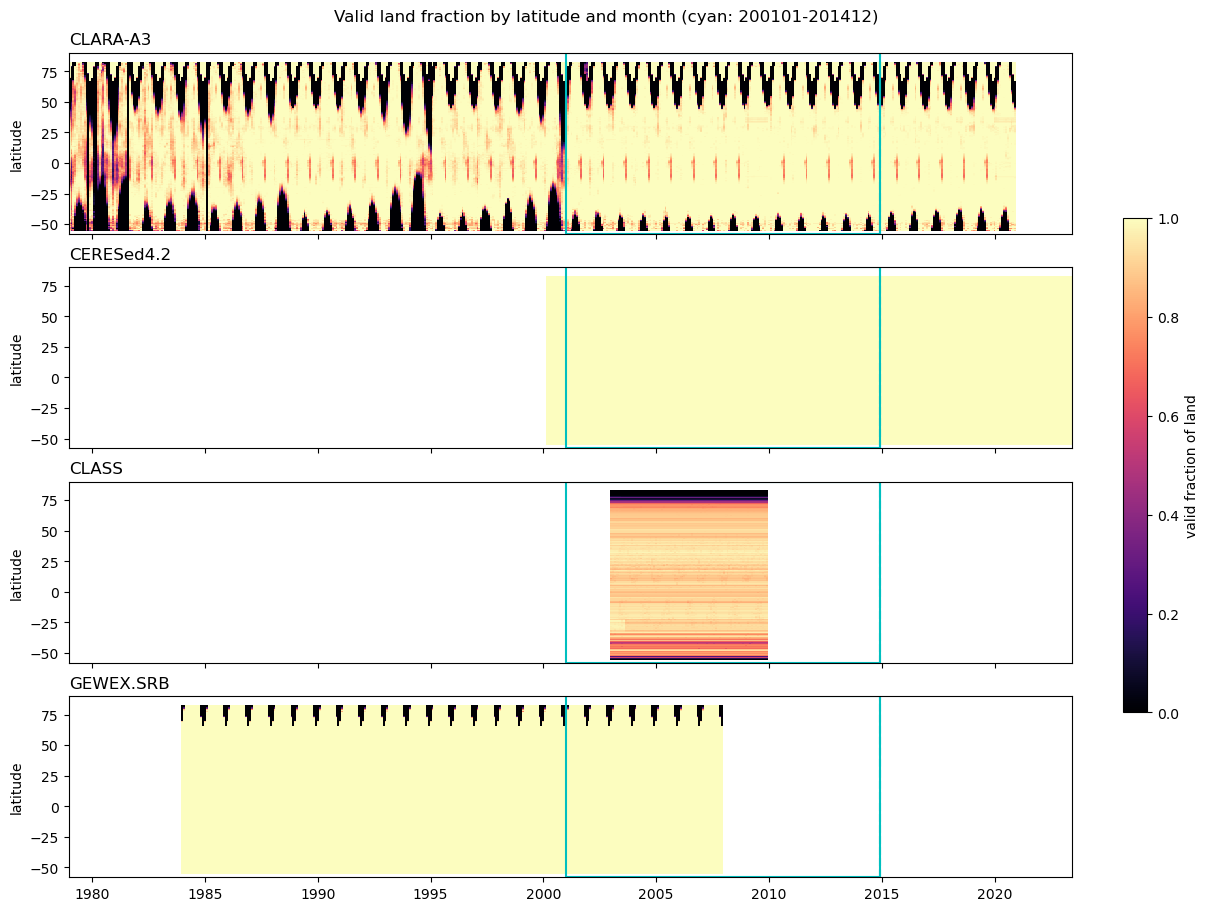

In [25]:
fig, axs = plt.subplots(len(PRODUCTS), 1, figsize=(12, 9), sharex=True, layout="constrained")
for ax, p in zip(axs, PRODUCTS):
    # Fraction of the land area of each latitude row with valid data, per month
    zonal = ((valid[p] * area[p]).sum("lon") / area[p].sum("lon")).where(area[p].sum("lon") > 0)
    im = ax.pcolormesh(zonal.time, zonal.lat, zonal.T, vmin=0, vmax=1, cmap="magma", shading="nearest")
    ax.axvspan(pd.Timestamp(TIME_SLICE.start), pd.Timestamp(TIME_SLICE.stop), facecolor="none", edgecolor="c", lw=1.5)
    ax.set_title(p, loc="left")
    ax.set_ylabel("latitude")
    ax.axvline(pd.Timestamp("2014-12"), color="c", ls="--")
    ax.set_ylim(cfg.LAT_BNDS.start, cfg.LAT_BNDS.stop)
fig.colorbar(im, ax=axs, shrink=0.6, label="valid fraction of land")
fig.suptitle(f"Valid land fraction by latitude and month (cyan: {PERIOD})")
plt.show()

## 3. Timeseries of global and regional area-weighted averages

Monthly valid land area (as a fraction of the region's land) and area-weighted mean Rn over the valid land of
each product. The mean Rn of a month covers only that month's valid land, so CLARA-A3's winter gaps at
mid/high latitudes bias its regional means high there. The last figure removes this effect by comparing each
ILAMB product with CLARA-A3 on the target grid over the cells valid in both in each month.

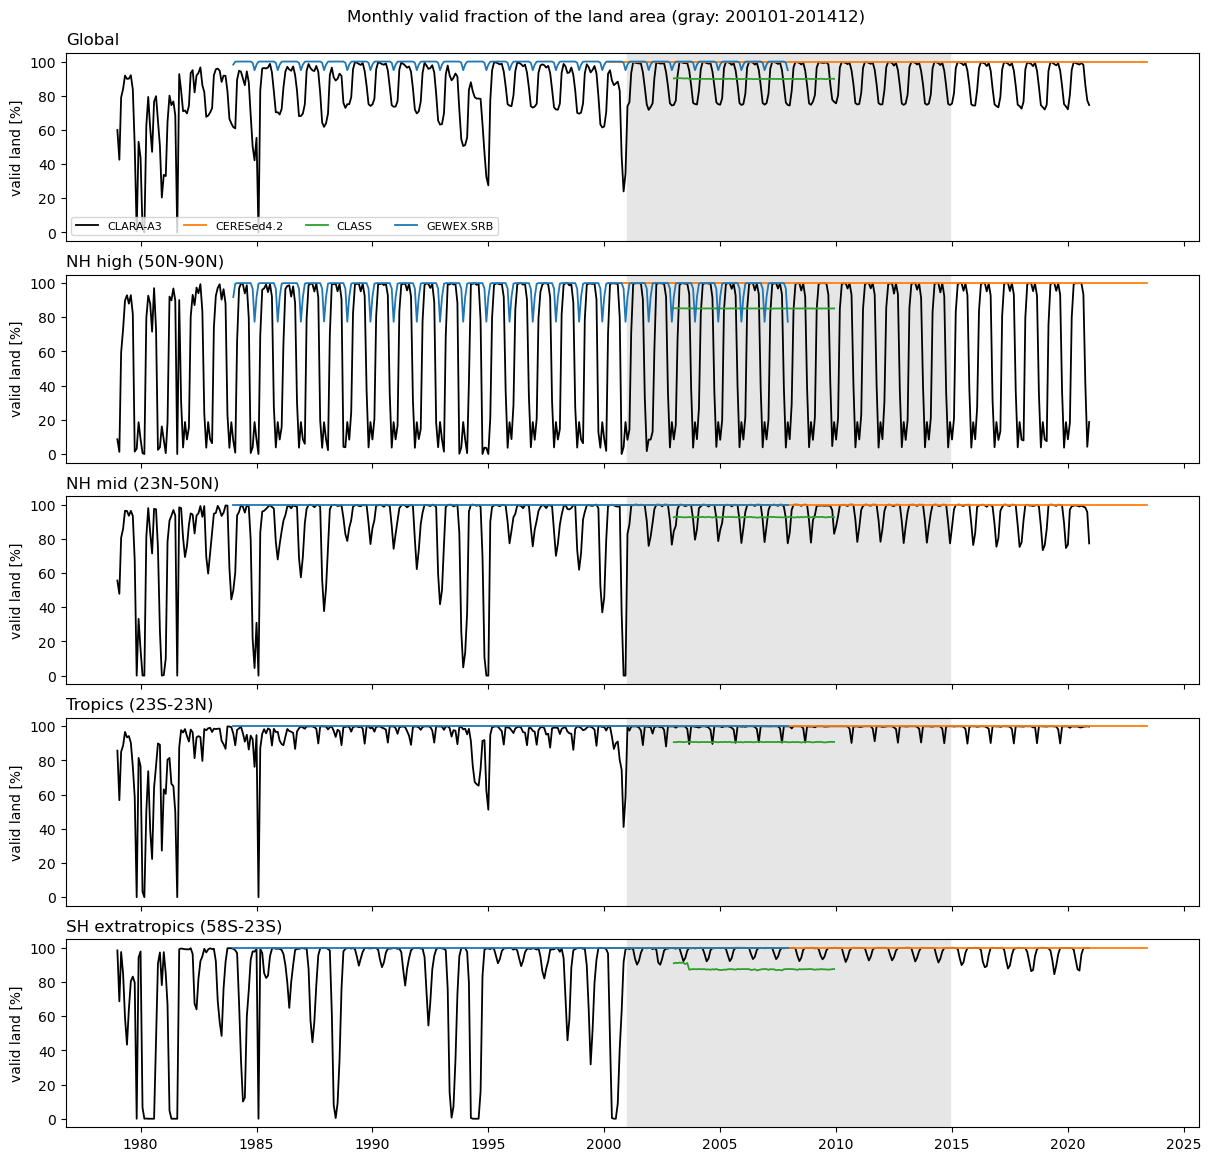

In [13]:
# Zonal sums over land, so each latitude band only needs a sum over lat: valid land area and area-weighted Rn
zonal_area = {p: (valid[p] * area[p]).sum("lon") for p in PRODUCTS}
zonal_rn = {p: xr.dot(rn[p].where(valid[p], 0), area[p], dim="lon") for p in PRODUCTS}
zonal_land = {p: area[p].sum("lon") for p in PRODUCTS}

cover, mean_rn = {}, {}
for r, b in REGIONS.items():
    band = lambda zonal: zonal.sel(lat=b).sum("lat")
    cover[r] = {p: band(zonal_area[p]) / band(zonal_land[p]) for p in PRODUCTS}
    mean_rn[r] = {p: (band(zonal_rn[p]) / band(zonal_area[p])).where(band(zonal_area[p]) > 0) for p in PRODUCTS}


def annual(ts: xr.DataArray) -> xr.DataArray:
    """Calendar-year mean of a monthly series, only for years with 12 valid months, stamped mid-year."""
    ann = ts.groupby("time.year").mean().where(ts.notnull().groupby("time.year").sum() == 12)
    return ann.assign_coords(year=pd.to_datetime([f"{y}-07-01" for y in ann.year.values])).rename(year="time")


def plot_regions(series: dict, ylabel: str, title: str, annual_mean: bool = False, zero_line: bool = False):
    """One panel per region; one line per product, monthly (thin) and optionally annual means (thick)."""
    fig, axs = plt.subplots(len(series), 1, figsize=(12, 2.3 * len(series)), sharex=True, layout="constrained")
    for ax, (r, by_product) in zip(axs, series.items()):
        for p, ts in by_product.items():
            ax.plot(ts.time, ts, color=COLORS[p], lw=0.7 if annual_mean else 1.3, alpha=0.5 if annual_mean else 1,
                    label=None if annual_mean else p)
            if annual_mean:
                ann = annual(ts)
                ax.plot(ann.time, ann, color=COLORS[p], lw=2, marker="o", ms=3, label=p)
        ax.axvspan(pd.Timestamp(TIME_SLICE.start), pd.Timestamp(TIME_SLICE.stop), color="0.9", zorder=0)
        if zero_line:
            ax.axhline(0, color="gray", lw=0.8)
        ax.set_title(r, loc="left")
        ax.set_ylabel(ylabel)
    axs[0].legend(ncols=len(PRODUCTS), fontsize=8, loc="lower left")
    fig.suptitle(title)
    plt.show()


plot_regions({r: {p: 100 * ts for p, ts in c.items()} for r, c in cover.items()}, "valid land [%]",
             f"Monthly valid fraction of the land area (gray: {PERIOD})")

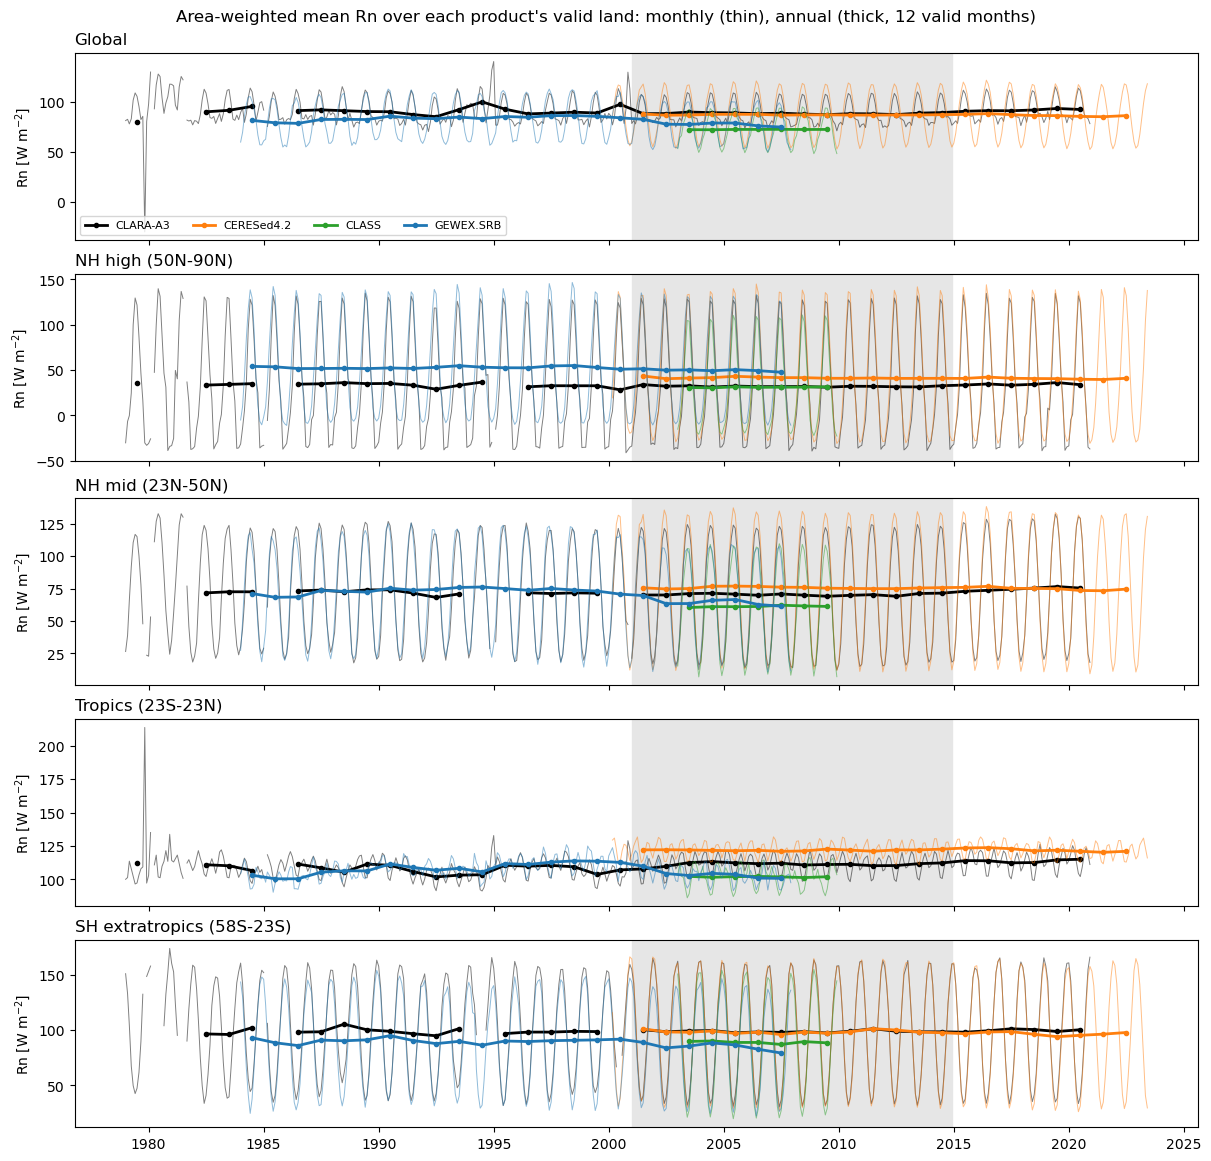

In [14]:
plot_regions(mean_rn, "Rn [W m$^{-2}$]",
             "Area-weighted mean Rn over each product's valid land: monthly (thin), annual (thick, 12 valid months)",
             annual_mean=True)

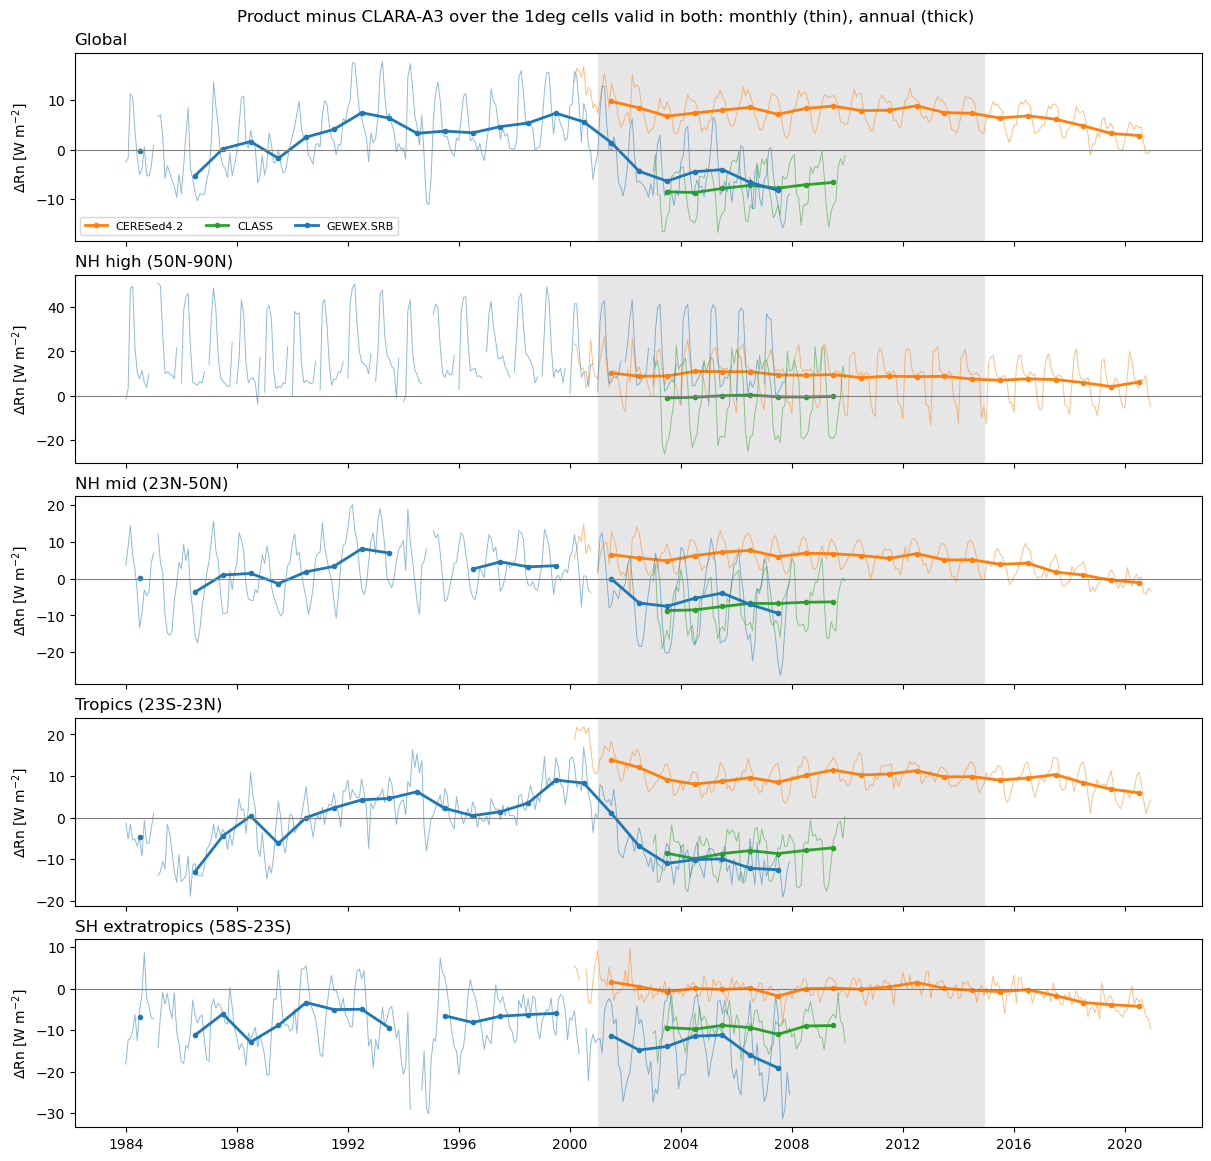

In [15]:
# Monthly Rn on the target grid (land only; NaN where more than NA_THRESH of a target cell is missing)
mon1 = {}
for p in PRODUCTS:
    da = rn[p].where(land[p])
    regridder = rg.bounded_conservative_regridder(rg.bounded_src_grid(da), TARGET_RES)
    mon1[p] = rg.on_grid(rg.regrid_with_na_thresh(da, regridder, cfg.NA_THRESH), TARGET_RES, p).sel(lat=cfg.LAT_BNDS)

# ILAMB product minus CLARA-A3, area-weighted over the target cells valid in both in each month
diff_rn = {r: {} for r in REGIONS}
for p in ILAMB_RN:
    a, c = xr.align(mon1[p], mon1["CLARA-A3"], join="inner")  # months in both records
    w = land_area1.where(a.notnull() & c.notnull(), 0)
    for r, b in REGIONS.items():
        wb = w.sel(lat=b)
        diff_rn[r][p] = (((a - c).sel(lat=b) * wb).sum(["lat", "lon"]) / wb.sum(["lat", "lon"])).where(wb.sum(["lat", "lon"]) > 0)

plot_regions(diff_rn, "$\\Delta$Rn [W m$^{-2}$]",
             f"Product minus CLARA-A3 over the {rg.grid_tag(TARGET_RES)} cells valid in both: monthly (thin), annual (thick)",
             annual_mean=True, zero_line=True)

## 4. Climatological Rn

Climatological Rn on the target grid as the pipeline computes it (`clim1`, over each product's complete years in
`TIME_SLICE`), and the mean difference from CLARA-A3 over the years in which both have a complete year.

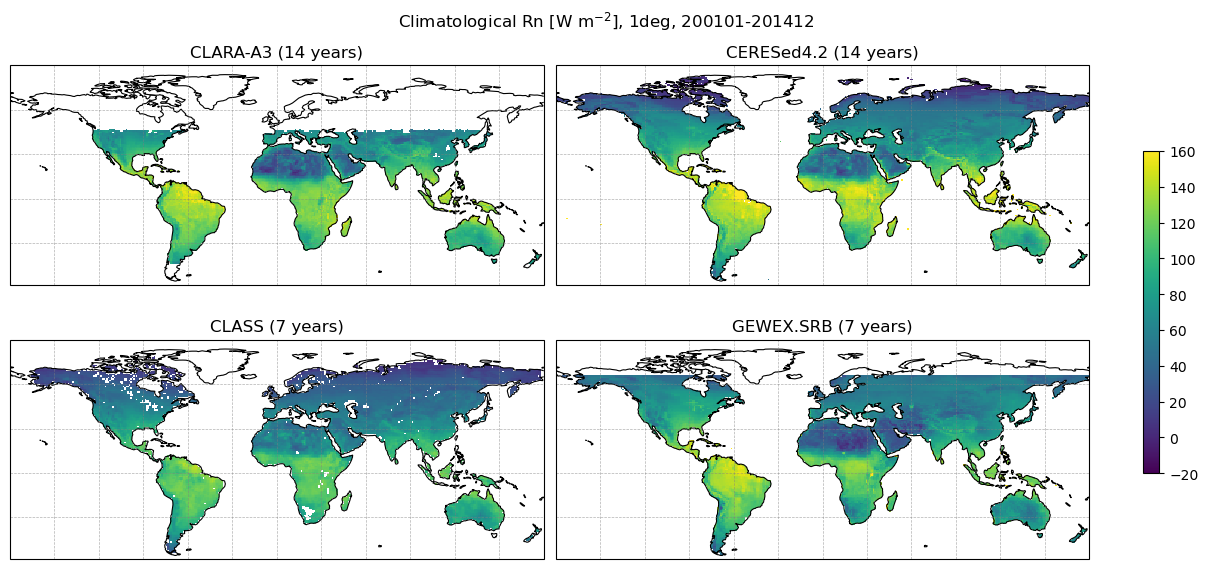

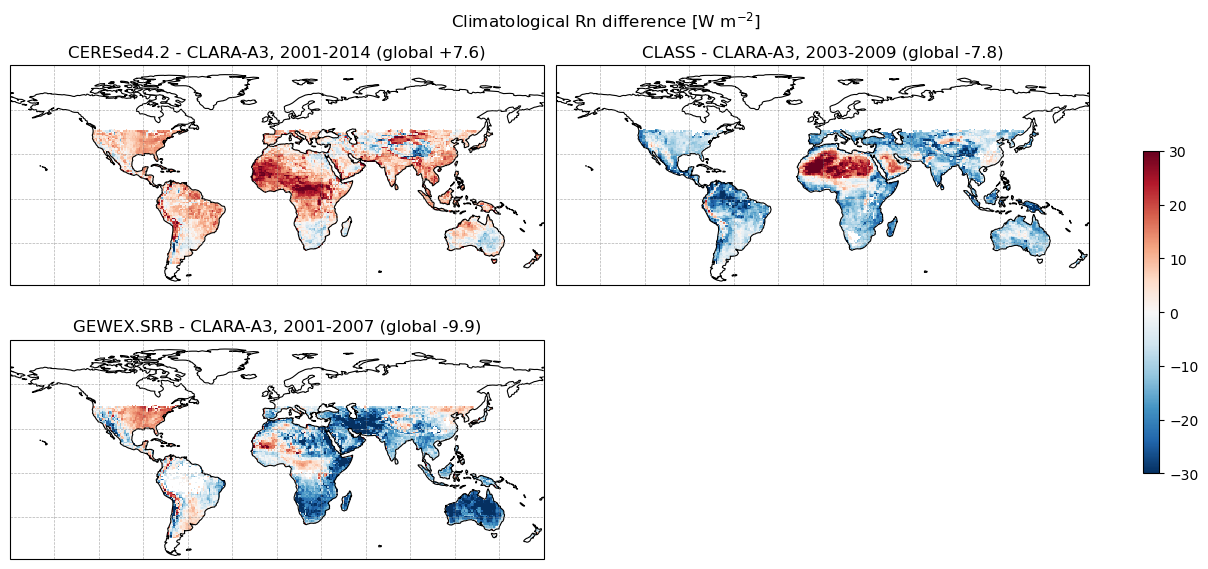

In [16]:
map_panels({f"{p} ({n_years[p]} years)": clim1[p] for p in PRODUCTS},
           f"Climatological Rn [W m$^{{-2}}$], {rg.grid_tag(TARGET_RES)}, {PERIOD}", vmin=-20, vmax=160, cmap="viridis")

diff_clim = {}
for p in ILAMB_RN:
    a, c = xr.align(ann1[p], ann1["CLARA-A3"], join="inner")  # shared years
    # Mean over the years in which both are valid, so both cover the same years in each cell
    d = (a - c).mean("year")
    w = land_area1.where(d.notnull(), 0)
    years = f"{int(a.year.min())}-{int(a.year.max())}"
    diff_clim[f"{p} - CLARA-A3, {years} (global {float((d * w).sum() / w.sum()):+.1f})"] = d
map_panels(diff_clim, "Climatological Rn difference [W m$^{-2}$]", vmin=-30, vmax=30, cmap="RdBu_r")

## 5. Quantile binning with each Rn product

How the choice of Rn product changes the bins that gridcells fall in, following steps 9-14 of
`docs/binning-workflow.md`. LAI and P are the products of `prep_obs.py` (GIMMS_LAI4g, GPCPv2.3), so the AIs differ
only in their Rn:

- Steps 1-8 for LAI and P over `TIME_SLICE` (Rn: `ann1` above)
- Step 9: complete years shared by LAI, P and Rn, at least `MIN_YEARS`. ET is left out because it does not enter
  the edges. With `YEARS = "shared"`, every product uses the years that all of them share, so the products differ
  in their Rn but not in their years
- Steps 10-11: climatological LAI, P and Rn, and AI = Rn / LP
- Step 12: each product's valid area (LAI and a finite AI, as in `rg.valid_area` but without ET) and their common
  area
- Step 13: quantile edges (`N_YBINS` for LAI, `N_XBINS` for AI) from `edges.pooled_bin_edges`, with every gridcell
  weighing equally. They are computed for each product on its own valid area and on the common area, and pooled
  over the products on the common area with the products weighted equally, as the obs sources are in `pooled_obs`
- Step 14: each gridcell's bin, assigned as in `binning.bin_stats` (`[lower, upper)` bins, with out-of-range
  values clipped into the edge bins). Changes are relative to `REF_RN`, the Rn product of `prep_obs.py`

The LAI field is the same for every product, so its bins differ only through the valid area and, with
`YEARS = "own"`, the years.

In [17]:
# LAI and P products of prep_obs.py (ILAMB_PRODUCTS), so only Rn differs between the AIs
LAI_PRODUCT, PR_PRODUCT = "GIMMS_LAI4g", "GPCPv2.3"
REF_RN = "GEWEX.SRB"  # Rn product of prep_obs.py; bin changes are relative to it
# "own": each product over its complete years shared with LAI and P (as prep_obs.py does per combination);
# "shared": every product over the years shared by all of them
YEARS = "own"
N_BINS = {"lai": cfg.N_YBINS, "ai": cfg.N_XBINS}

# Steps 1-8 for LAI and P, as in prep_obs.py (a missing LAI month counts as 0)
ann_lp = {}
for v, p in (("lai", LAI_PRODUCT), ("pr", PR_PRODUCT)):
    label = f"{v}/{p}"
    da = il.load_native(v, p, TIME_SLICE)
    da = da.assign_attrs(units="m2/m2") if v == "lai" else units.flux_to_wm2(da)
    a = temporal.aggregate(da, "year", require_all_months=(v != "lai"), label=label)
    a = rg.mask_to_land(a, rg.landne_mask(a), label)
    regridder = rg.bounded_conservative_regridder(rg.bounded_src_grid(a), TARGET_RES)
    ann_lp[v] = rg.on_grid(rg.regrid_with_na_thresh(a, regridder, cfg.NA_THRESH), TARGET_RES, label).sel(lat=cfg.LAT_BNDS)

lai/GIMMS_LAI4g: annual means of 14 complete years; 30478 gridcell-years with partial (1-11) valid months, missing months counted as 0


/glade/work/bbuchovecky/miniforge3/envs/etunc/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


pr/GPCPv2.3: annual means of 14 complete years; 0 gridcell-years with partial (1-11) valid months, set to NaN


/glade/work/bbuchovecky/miniforge3/envs/etunc/lib/python3.12/site-packages/xesmf/smm.py:131: UserWarning: Input array is not C_CONTIGUOUS. Will affect performance.
  warnings.warn('Input array is not C_CONTIGUOUS. ' 'Will affect performance.')


In [18]:
# Step 9: complete years shared by LAI, P and Rn, at least MIN_YEARS
years = {}
for p in PRODUCTS:
    y = temporal.shared_years(ann_lp["lai"], ann_lp["pr"], ann1[p])
    if len(y) < cfg.MIN_YEARS:
        print(f"{p}: {len(y)} shared years < MIN_YEARS = {cfg.MIN_YEARS}, skipping")
        continue
    years[p] = y
if YEARS == "shared":
    y = sorted(set.intersection(*(set(y) for y in years.values())))
    assert len(y) >= cfg.MIN_YEARS, f"{list(years)} share {len(y)} years < MIN_YEARS = {cfg.MIN_YEARS}"
    years = {p: y for p in years}
RN_BIN = list(years)  # Rn products binned
assert REF_RN in RN_BIN, f"{REF_RN} has fewer than MIN_YEARS complete years in {PERIOD}"
others = [p for p in RN_BIN if p != REF_RN]
for p, y in years.items():
    print(f"{p:11}: {min(y)}-{max(y)} ({len(y)} years)")

# Steps 10-11: climatological LAI, P and Rn over those years, and the AI; one member per Rn product
lai_rn, ai_rn = [], []
for p, y in years.items():
    clim = {v: temporal.aggregate(da.sel(year=y), "clim", label=f"{p}/{v}")
            for v, da in {**ann_lp, "rn": ann1[p]}.items()}
    lai_rn.append(clim["lai"])
    ai_rn.append(edges.compute_aridity_index(clim["pr"], clim["rn"]))
lai_rn = xr.concat(lai_rn, "member").assign_coords(member=RN_BIN, source=("member", RN_BIN))
ai_rn = xr.concat(ai_rn, "member").assign_coords(member=RN_BIN, source=("member", RN_BIN))
fields = {"lai": lai_rn, "ai": ai_rn}

# Step 12: each product's valid area (rg.valid_area without ET) and their common area
valid_rn = {p: (lai_rn.notnull() & np.isfinite(ai_rn)).sel(member=p, drop=True).reset_coords(drop=True)
            for p in RN_BIN}
common_rn = rg.common_area(valid_rn)

CLARA-A3   : 2001-2014 (14 years)
CERESed4.2 : 2001-2014 (14 years)
CLASS      : 2003-2009 (7 years)
GEWEX.SRB  : 2001-2007 (7 years)
CLARA-A3/lai: climatology of 14 years; 0 gridcells have missing years
CLARA-A3/pr: climatology of 14 years; 0 gridcells have missing years
CLARA-A3/rn: climatology of 14 years; 2191 gridcells have missing years (fewest valid years: 1)
CERESed4.2/lai: climatology of 14 years; 0 gridcells have missing years
CERESed4.2/pr: climatology of 14 years; 0 gridcells have missing years
CERESed4.2/rn: climatology of 14 years; 0 gridcells have missing years
CLASS/lai: climatology of 7 years; 0 gridcells have missing years
CLASS/pr: climatology of 7 years; 0 gridcells have missing years
CLASS/rn: climatology of 7 years; 565 gridcells have missing years (fewest valid years: 1)
GEWEX.SRB/lai: climatology of 7 years; 0 gridcells have missing years
GEWEX.SRB/pr: climatology of 7 years; 0 gridcells have missing years
GEWEX.SRB/rn: climatology of 7 years; 0 gridcells have m

### Quantile edges

Edges of each product on its own valid area (the effect of its coverage and its values) and on the common area
(the effect of its values only), and the pooled edges. The last edge, the maximum, is not shown.

lai: 6.983e+03 values, [0.0101, 6.2], 0.0% of weight at 0 -> edges [0.01  0.223 0.307 0.405 0.552 0.762 0.988 1.231 1.523 1.812 2.072 2.368
 2.893 4.041 5.306 6.201]
lai: 1.271e+04 values, [0.001, 6.2], 0.0% of weight at 0 -> edges [1.000e-03 2.170e-01 3.150e-01 4.010e-01 4.870e-01 6.010e-01 7.490e-01
 9.280e-01 1.131e+00 1.352e+00 1.585e+00 1.814e+00 2.054e+00 2.532e+00
 4.268e+00 6.201e+00]
lai: 1.167e+04 values, [0.000669, 6.21], 0.0% of weight at 0 -> edges [1.000e-03 2.280e-01 3.210e-01 4.070e-01 4.950e-01 6.110e-01 7.620e-01
 9.350e-01 1.134e+00 1.353e+00 1.573e+00 1.797e+00 2.039e+00 2.518e+00
 4.422e+00 6.210e+00]
lai: 1.152e+04 values, [0.0134, 6.2], 0.0% of weight at 0 -> edges [0.013 0.241 0.341 0.45  0.592 0.747 0.921 1.104 1.288 1.5   1.709 1.909
 2.166 2.765 4.586 6.2  ]
ai: 6.983e+03 values, [0.325, 90.2], 0.0% of weight at 0 -> edges [ 0.325  0.65   0.759  0.862  0.949  1.044  1.187  1.337  1.515  1.721
  1.998  2.31   2.797  3.399  4.385 90.163]
ai: 1.271e+04 values, [

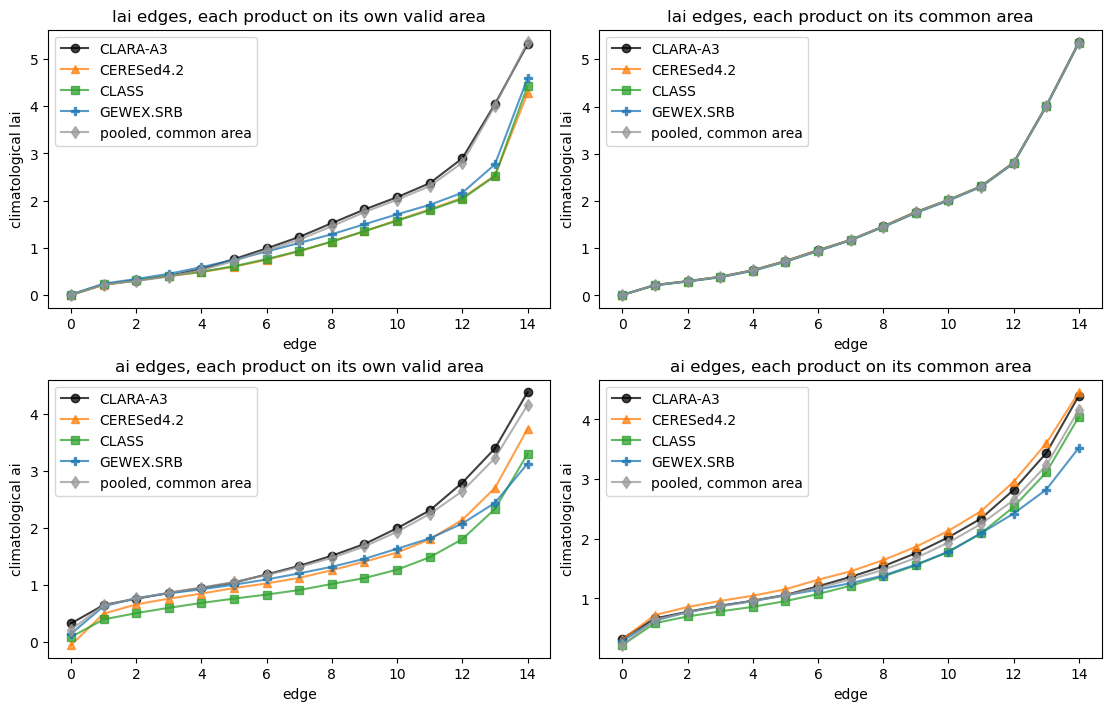

AI edges on the common area


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15
CLARA-A3,0.33,0.66,0.78,0.87,0.96,1.06,1.20,1.36,1.54,1.76,2.02,2.34,2.82,3.44,4.40,90.16
CERESed4.2,0.31,0.72,0.85,0.96,1.04,1.15,1.31,1.45,1.64,1.86,2.13,2.46,2.95,3.60,4.46,80.44
CLASS,0.22,0.58,0.70,0.78,0.86,0.95,1.07,1.21,1.37,1.55,1.78,2.09,2.53,3.11,4.05,117.15
GEWEX.SRB,0.29,0.63,0.77,0.87,0.95,1.05,1.15,1.25,1.38,1.57,1.78,2.09,2.42,2.82,3.53,58.95
pooled,0.22,0.64,0.77,0.86,0.96,1.05,1.18,1.32,1.48,1.68,1.94,2.25,2.65,3.23,4.16,117.15


In [19]:
def quantile_edges(field: xr.DataArray, area: xr.DataArray, v: str) -> xr.DataArray:
    """Step 13: quantile edges of `field` (member, lat, lon) on `area`, its sources weighted equally."""
    values, weights = edges.hierarchical_weights({"rn": field.where(area)})
    return edges.pooled_bin_edges(values, weights, N_BINS[v], name=v)


# {area: {variable: {product: edges}}}, and the pooled edges {variable: edges} shared by every product
edge_sets = {
    "own valid area": {v: {p: quantile_edges(f.sel(member=[p]), valid_rn[p], v) for p in RN_BIN}
                       for v, f in fields.items()},
    "common area": {v: {p: quantile_edges(f.sel(member=[p]), common_rn, v) for p in RN_BIN}
                    for v, f in fields.items()},
}
pooled_edges = {v: quantile_edges(f, common_rn, v) for v, f in fields.items()}

fig, axs = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
for j, (kind, by_var) in enumerate(edge_sets.items()):
    for i, v in enumerate(fields):
        axs[i, j].set_prop_cycle(color=[COLORS[p] for p in RN_BIN] + ["0.6"])
        plotting.plot_edges_compare({**by_var[v], "pooled, common area": pooled_edges[v]}, ax=axs[i, j],
                                    title=f"{v} edges, each product on its {kind}")
        axs[i, j].set_ylabel(f"climatological {v}")
plt.show()

print("AI edges on the common area")
pd.DataFrame({p: e.values for p, e in {**edge_sets["common area"]["ai"], "pooled": pooled_edges["ai"]}.items()}).T.round(2)

lai, own valid area: values outside [0, 8], counted in the end bins: up to 0.00% (CLARA-A3)
ai, own valid area: values outside [-1, 10], counted in the end bins: up to 0.37% (CLARA-A3)
ai, common area: values outside [-1, 10], counted in the end bins: up to 0.54% (CERESed4.2)


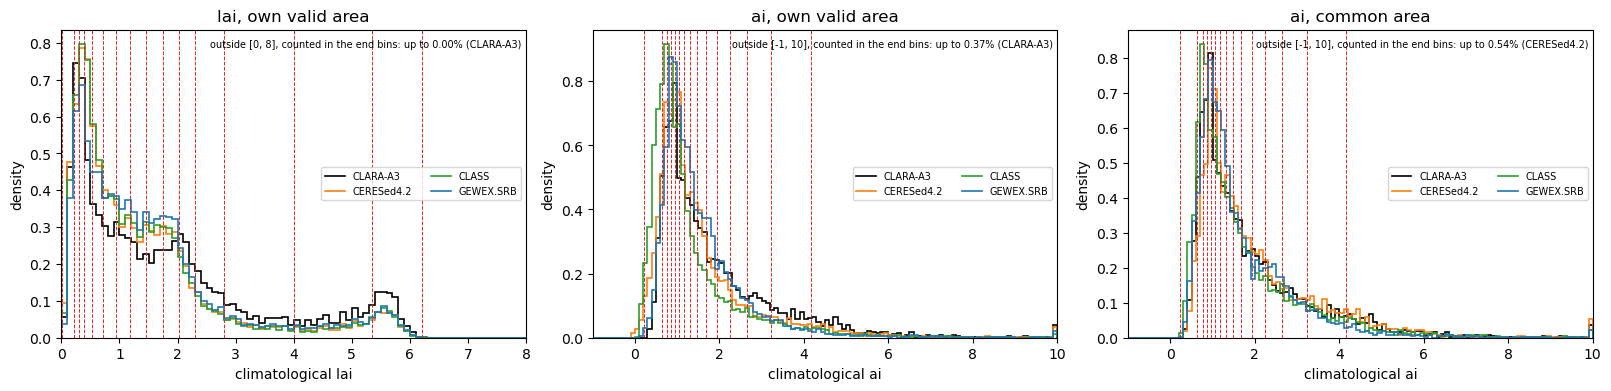

In [20]:
# Distributions behind the edges, with the pooled edges (red)
panels = [
    ("lai", {p: valid_rn[p] for p in RN_BIN}, "own valid area"),
    ("ai", {p: valid_rn[p] for p in RN_BIN}, "own valid area"),
    ("ai", {p: common_rn for p in RN_BIN}, "common area"),
]
fig, axs = plt.subplots(1, 3, figsize=(16, 3.8), layout="constrained")
for ax, (v, area_of, kind) in zip(axs, panels):
    ax.set_prop_cycle(color=[COLORS[p] for p in RN_BIN])
    plotting.plot_clim_hist({p: fields[v].sel(member=p).where(area_of[p]) for p in RN_BIN}, cfg.HIST_BINS[v],
                            edges=pooled_edges[v], xlabel=f"climatological {v}", title=f"{v}, {kind}", ax=ax)
plt.show()

### Bin changes of the gridcells

Each common-area gridcell's LAI and AI bins with each product, compared with `REF_RN`, using two kinds of edges:
- **Pooled edges**, one set for every product as in the pipeline. A gridcell changes bin when its AI crosses an
  edge, so this shows the effect of the product's Rn on the binned AI.
- **Each product's own edges** on the common area. A gridcell changes bin when its rank among the gridcells changes,
  so this shows the effect of the spatial pattern of the product's AI, without its global level.

On the common area the LAI field is the same for every product with `YEARS = "shared"`, so then only the AI bins
change. The percentages are of the common-area gridcells, which are unweighted in the bins by default
(`AREA_WEIGHTED = False`). A positive AI bin change is a drier bin.

In [21]:
def bin_index(field: xr.DataArray, e: xr.DataArray) -> xr.DataArray:
    """
    Bin of each value as in binning.bin_stats: [lower, upper) bins, with out-of-range values clipped into the edge
    bins. NaN where `field` is not finite.
    """
    n = e.sizes["edge"] - 1
    idx = np.clip(np.searchsorted(e.values, field.values, side="right") - 1, 0, n - 1)
    return xr.DataArray(idx, coords=field.coords, dims=field.dims).where(np.isfinite(field))


# LAI and AI bin of each common-area gridcell (member, lat, lon), with the pooled edges and with each product's
# own edges on the common area
on_common = {v: f.where(common_rn) for v, f in fields.items()}
bins = {
    "pooled edges": {v: bin_index(on_common[v], pooled_edges[v]) for v in fields},
    "own edges": {
        v: xr.concat([bin_index(on_common[v].sel(member=p), edge_sets["common area"][v][p]).reset_coords(drop=True)
                      for p in RN_BIN], "member").assign_coords(member=RN_BIN, source=("member", RN_BIN))
        for v in fields
    },
}

cells = common_rn.values  # common-area gridcells, flattened by boolean indexing below
rows = {}
for kind, b in bins.items():
    for p in others:
        d_ai = (b["ai"].sel(member=p) - b["ai"].sel(member=REF_RN)).values[cells]
        d_lai = (b["lai"].sel(member=p) - b["lai"].sel(member=REF_RN)).values[cells]
        rows[(kind, p)] = {
            "same AI bin": np.mean(d_ai == 0),
            "AI bin +-1": np.mean(np.abs(d_ai) == 1),
            "AI bin +-2": np.mean(np.abs(d_ai) == 2),
            "AI bin +-3 or more": np.mean(np.abs(d_ai) >= 3),
            "same LAI bin": np.mean(d_lai == 0),
            "same LAI-AI bin": np.mean((d_ai == 0) & (d_lai == 0)),
        }
print(f"% of the {int(cells.sum())} common-area gridcells, relative to {REF_RN}, {N_BINS['lai']} LAI x "
      f"{N_BINS['ai']} AI bins")
(100 * pd.DataFrame(rows).T).round(1)

% of the 6524 common-area gridcells, relative to GEWEX.SRB, 15 LAI x 15 AI bins


same AI bin  AI bin +-1  AI bin +-2  \
pooled edges CLARA-A3           36.3        41.4        15.9   
             CERESed4.2         30.4        39.8        20.6   
             CLASS              34.3        41.0        16.2   
own edges    CLARA-A3           39.7        42.2        12.3   
             CERESed4.2         38.8        43.7        12.8   
             CLASS              37.8        40.7        15.0   

                         AI bin +-3 or more  same LAI bin  same LAI-AI bin  
pooled edges CLARA-A3                   6.4          91.4             33.2  
             CERESed4.2                 9.3          91.4             28.0  
             CLASS                      8.5          94.9             32.8  
own edges    CLARA-A3                   5.8          92.1             36.4  
             CERESed4.2                 4.7          92.1             35.6  
             CLASS                      6.5          95.3             36.1

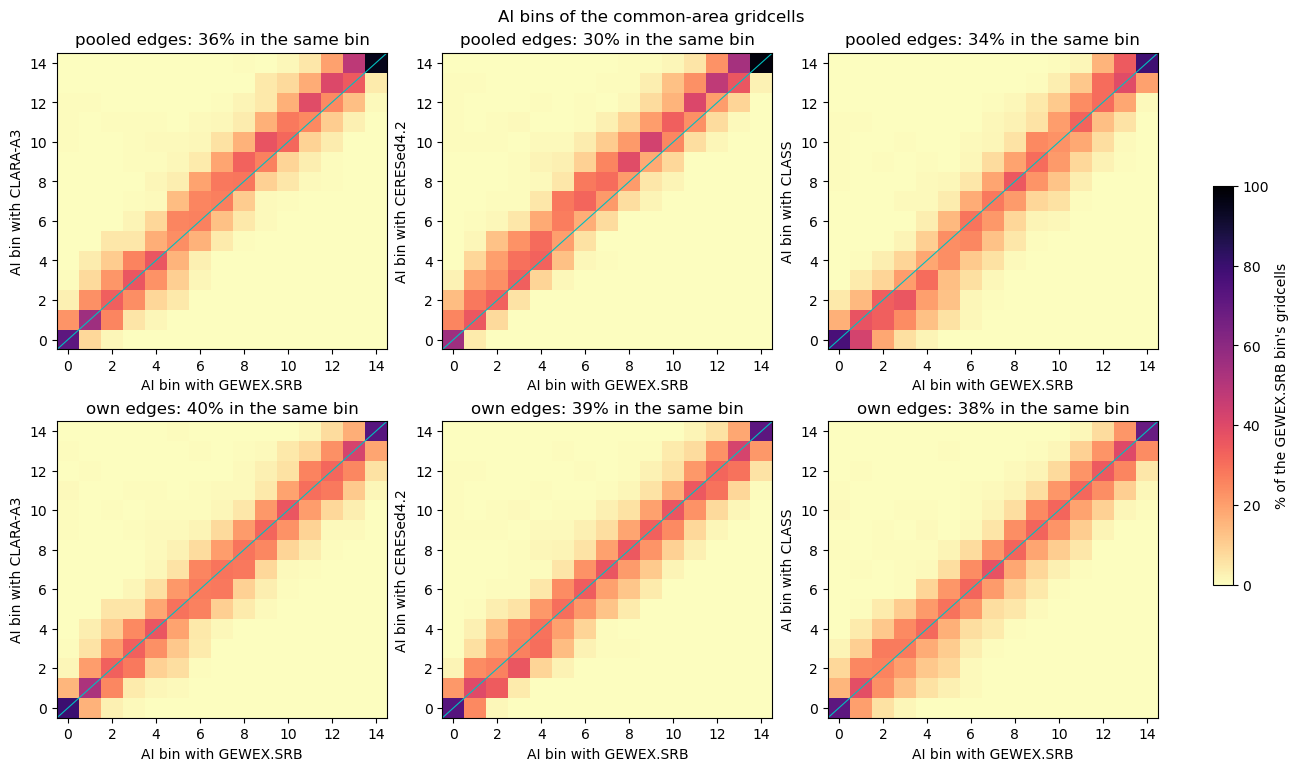

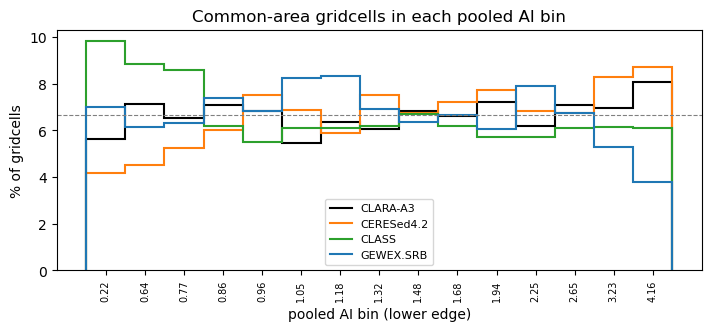

In [22]:
# Where the gridcells go: AI bin with REF_RN (x) against the AI bin with each other product (y), as % of the
# REF_RN bin's gridcells (each column sums to 100)
n = N_BINS["ai"]
fig, axs = plt.subplots(len(bins), len(others), figsize=(4.3 * len(others), 3.8 * len(bins)), layout="constrained",
                        squeeze=False)
for i, (kind, b) in enumerate(bins.items()):
    ref = b["ai"].sel(member=REF_RN).values[cells]
    for ax, p in zip(axs[i], others):
        h, _, _ = np.histogram2d(ref, b["ai"].sel(member=p).values[cells], bins=np.arange(n + 1) - 0.5)
        with np.errstate(invalid="ignore"):
            pct = 100 * h / h.sum(axis=1, keepdims=True)
        pm = ax.pcolormesh(np.arange(n + 1) - 0.5, np.arange(n + 1) - 0.5, pct.T, cmap="magma_r", vmin=0, vmax=100)
        ax.plot([-0.5, n - 0.5], [-0.5, n - 0.5], color="c", lw=0.8)
        ax.set_xticks(range(0, n, 2))
        ax.set_yticks(range(0, n, 2))
        ax.set_xlabel(f"AI bin with {REF_RN}")
        ax.set_ylabel(f"AI bin with {p}")
        ax.set_title(f"{kind}: {100 * np.trace(h) / h.sum():.0f}% in the same bin")
fig.colorbar(pm, ax=axs, shrink=0.6, label=f"% of the {REF_RN} bin's gridcells")
fig.suptitle("AI bins of the common-area gridcells")
plt.show()

# Distribution of the gridcells across the pooled AI bins (with each product's own edges, every bin holds 1/n)
fig, ax = plt.subplots(figsize=(7, 3.2), layout="constrained")
for p in RN_BIN:
    b = bins["pooled edges"]["ai"].sel(member=p).values[cells].astype(int)
    ax.stairs(100 * np.bincount(b, minlength=n) / b.size, np.arange(n + 1) - 0.5, color=COLORS[p], lw=1.5, label=p)
ax.axhline(100 / n, color="gray", ls="--", lw=0.8)
ax.set_xticks(range(n), [f"{e:.2f}" for e in pooled_edges["ai"].values[:-1]], rotation=90, fontsize=7)
ax.set_xlabel("pooled AI bin (lower edge)")
ax.set_ylabel("% of gridcells")
ax.set_title("Common-area gridcells in each pooled AI bin")
ax.legend(fontsize=8)
plt.show()

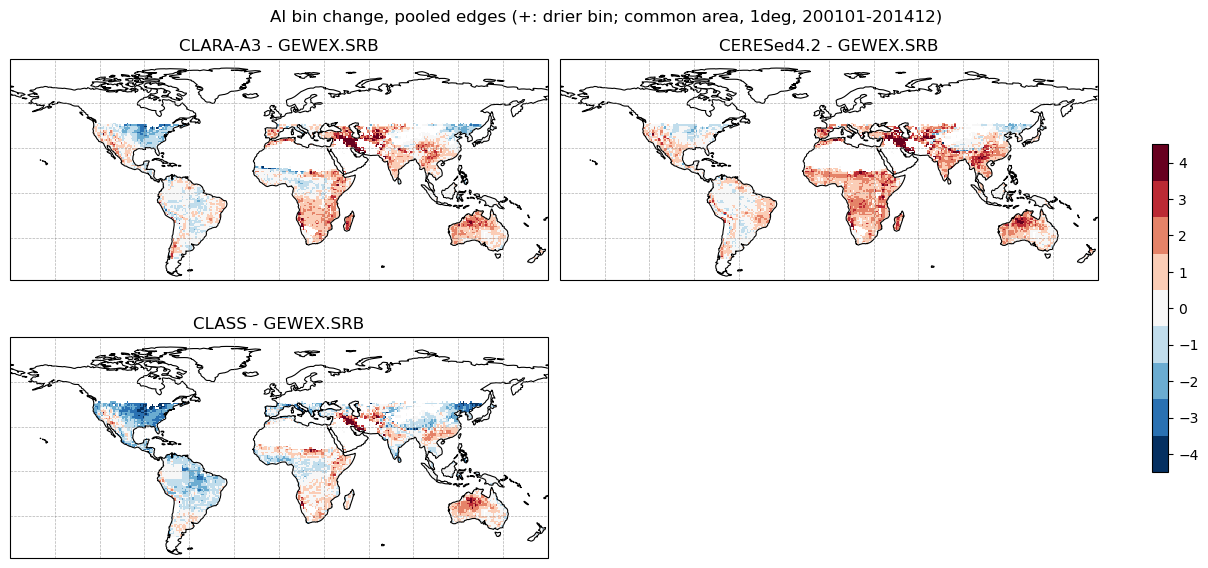

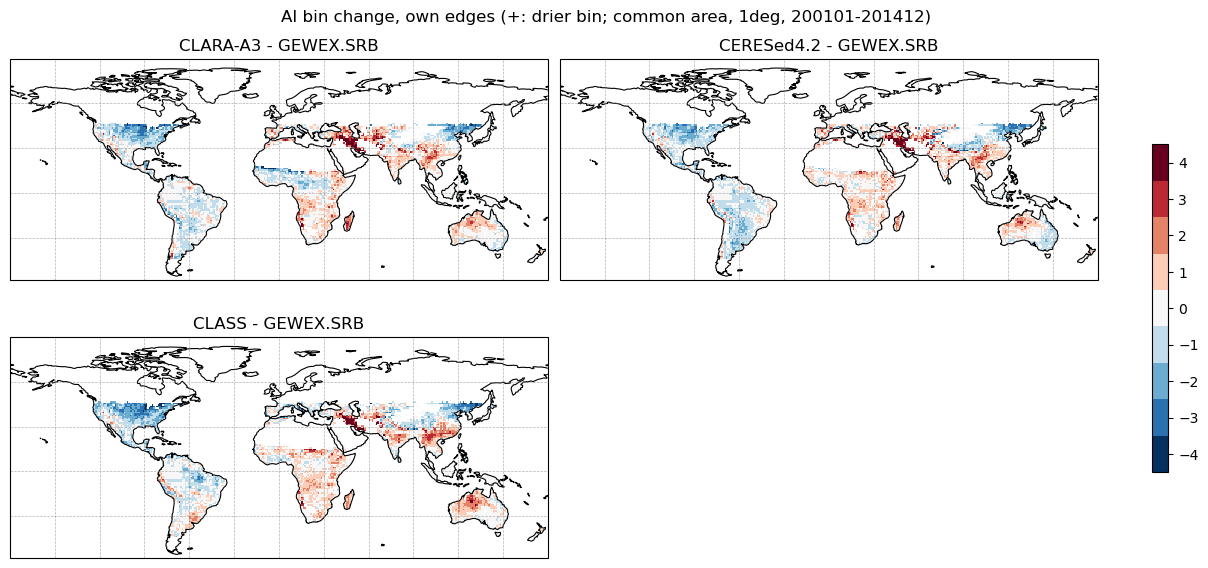

In [23]:
# Maps of the AI bin change from REF_RN (+: drier bin)
for kind, b in bins.items():
    shift = {f"{p} - {REF_RN}": b["ai"].sel(member=p) - b["ai"].sel(member=REF_RN) for p in others}
    map_panels(shift, f"AI bin change, {kind} (+: drier bin; common area, {rg.grid_tag(TARGET_RES)}, {PERIOD})",
               cmap=plt.get_cmap("RdBu_r", 9), vmin=-4.5, vmax=4.5)

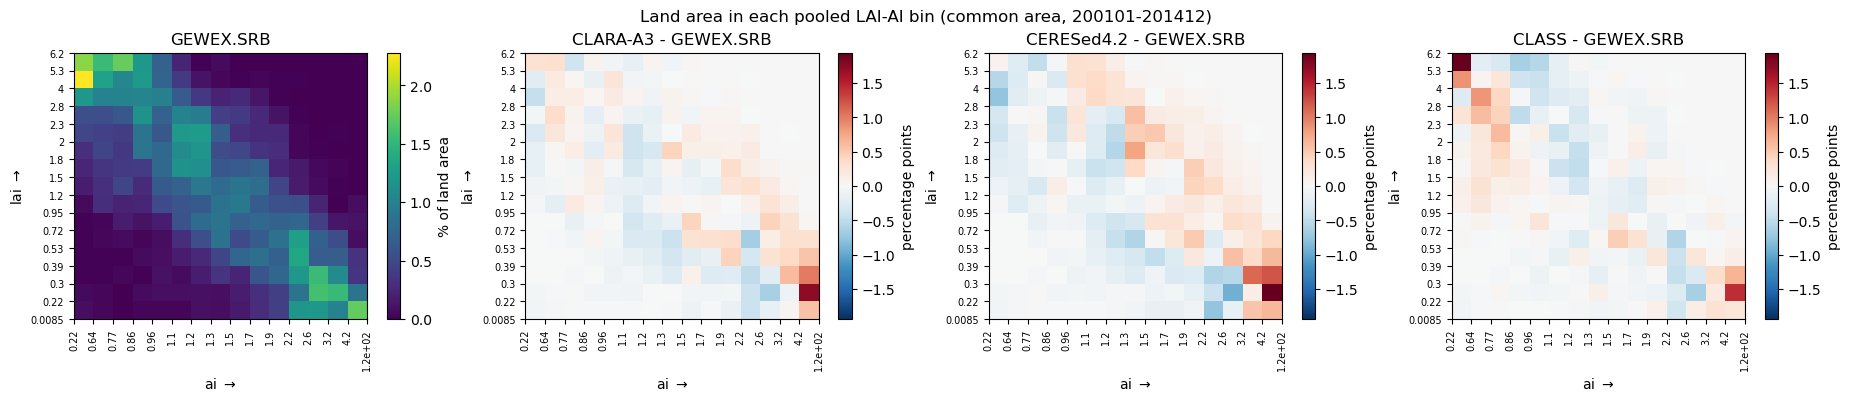

In [24]:
# Land area in each LAI-AI bin with the pooled edges, as bin_area.py does (bin total = mean x count of the
# gridcells' land area), in % of the common area's land area
bs = binning.bin_stats(
    land_area1.expand_dims(member=RN_BIN), lai_rn, ai_rn, pooled_edges["lai"], pooled_edges["ai"],
    mask=common_rn, member_dim="member", name="land_area",
)
bs = binning.drop_zero_width_bins(bs)
with xr.set_options(keep_attrs=True):  # keeps the bin variable names for the axis labels
    area_pct = 100 * bs.sel(stats="mean").fillna(0) * bs.sel(stats="count") / float(land_area1.where(common_rn).sum())
    diff_pct = {p: area_pct.sel(member=p) - area_pct.sel(member=REF_RN) for p in others}

vmax = max(float(abs(d).max()) for d in diff_pct.values())
fig, axs = plotting.facets(len(RN_BIN), ncols=len(RN_BIN), panel_size=(4.6, 3.9))
plotting.plot_bin_field(area_pct.sel(member=REF_RN), ax=axs[0], cmap="viridis", vmin=0,
                        cbar_kwargs={"label": "% of land area"}, title=REF_RN)
for ax, (p, d) in zip(axs[1:], diff_pct.items()):
    plotting.plot_bin_field(d, ax=ax, cmap="RdBu_r", vmin=-vmax, vmax=vmax, cbar_kwargs={"label": "percentage points"},
                            title=f"{p} - {REF_RN}")
fig.suptitle(f"Land area in each pooled LAI-AI bin (common area, {PERIOD})")
plt.show()